In [ ]:
!pip install -q geopandas shapely pyogrio folium

In [ ]:
import os
import glob
import warnings
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
DRIVE_ROOT = "/content/drive/MyDrive"

# Your actual folder name contains a trailing space
PROJECT_ROOT = os.path.join(
    DRIVE_ROOT,
    "Smart_Ride_Intelligence"
)

if not os.path.exists(PROJECT_ROOT):
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}"
    )

print("Project folder found!")
print("Project path:", PROJECT_ROOT)

Project folder found!
Project path: /content/drive/MyDrive/Smart_Ride_Intelligence


In [ ]:
for root, dirs, files in os.walk(PROJECT_ROOT):
    level = root.replace(PROJECT_ROOT, "").count(os.sep)

    if level <= 3:
        indent = "    " * level
        print(f"{indent}{os.path.basename(root)}/")

        for file in files:
            if file.endswith((".csv", ".geojson")):
                print(f"{indent}    {file}")

Smart_Ride_Intelligence/
    datasets/
        raw/
            roads/
                major_roads.geojson
                link_roads.geojson
                national_highways.geojson
                state_highways.geojson
                flyovers.geojson
                traffic50.geojson
                traffic_junctions.geojson
                poi.geojson
                parking_north.geojson
                parking_southeast.geojson
                parking_southwest.geojson
        processed/
            forum_posts.csv
            forum_comments.csv
            forum_training.csv


In [ ]:
all_files = []

for root, dirs, files in os.walk(PROJECT_ROOT):
    for file in files:
        all_files.append(os.path.join(root, file))

# Locate GeoJSON files
geojson_files = {
    os.path.basename(path): path
    for path in all_files
    if path.lower().endswith(".geojson")
}

# Locate CSV files
csv_files = [
    path for path in all_files
    if path.lower().endswith(".csv")
]

print("GeoJSON files found:", len(geojson_files))
print("CSV files found:", len(csv_files))

print("\nGeoJSON files:")
for filename in sorted(geojson_files):
    print(filename)

print("\nCSV files:")
for filepath in csv_files:
    print(filepath)

GeoJSON files found: 11
CSV files found: 3

GeoJSON files:
flyovers.geojson
link_roads.geojson
major_roads.geojson
national_highways.geojson
parking_north.geojson
parking_southeast.geojson
parking_southwest.geojson
poi.geojson
state_highways.geojson
traffic50.geojson
traffic_junctions.geojson

CSV files:
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_posts.csv
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_comments.csv
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_training.csv


In [ ]:
expected_geojson = [
    "flyovers.geojson",
    "link_roads.geojson",
    "major_roads.geojson",
    "national_highways.geojson",
    "parking_north.geojson",
    "parking_southeast.geojson",
    "parking_southwest.geojson",
    "poi.geojson",
    "state_highways.geojson",
    "traffic_junctions.geojson",
    "traffic50.geojson"
]

missing_geojson = [
    name for name in expected_geojson
    if name not in geojson_files
]

print("Expected GeoJSON files:", len(expected_geojson))
print("Missing files:", missing_geojson)

Expected GeoJSON files: 11
Missing files: []


In [ ]:
#inspecting geojson files
geo_data = {}

for filename, filepath in geojson_files.items():

    try:
        gdf = gpd.read_file(filepath)
        geo_data[filename] = gdf

        print(f"\nLoaded: {filename}")
        print("Shape:", gdf.shape)
        print("CRS:", gdf.crs)

    except Exception as e:
        print(f"Error loading {filename}: {e}")


Loaded: major_roads.geojson
Shape: (1000, 11)
CRS: EPSG:4326

Loaded: link_roads.geojson
Shape: (1000, 11)
CRS: EPSG:4326

Loaded: national_highways.geojson
Shape: (456, 11)
CRS: EPSG:4326

Loaded: state_highways.geojson
Shape: (76, 11)
CRS: EPSG:4326

Loaded: flyovers.geojson
Shape: (42, 11)
CRS: EPSG:4326

Loaded: traffic50.geojson
Shape: (50, 12)
CRS: EPSG:4326

Loaded: traffic_junctions.geojson
Shape: (50, 12)
CRS: EPSG:4326

Loaded: poi.geojson
Shape: (1000, 3)
CRS: EPSG:4326

Loaded: parking_north.geojson
Shape: (21, 15)
CRS: EPSG:4326

Loaded: parking_southeast.geojson
Shape: (74, 15)
CRS: EPSG:4326

Loaded: parking_southwest.geojson
Shape: (39, 15)
CRS: EPSG:4326


In [ ]:
geo_inventory = []

for filename, gdf in geo_data.items():

    geo_inventory.append({
        "filename": filename,
        "feature_count": len(gdf),
        "column_count": len(gdf.columns),
        "geometry_types": ", ".join(
            map(str, gdf.geometry.geom_type.unique())
        ),
        "CRS": str(gdf.crs),
        "empty_geometries": gdf.geometry.is_empty.sum(),
        "missing_geometries": gdf.geometry.isna().sum(),
        "invalid_geometries": (
            (~gdf.geometry.is_valid).sum()
        )
    })

geo_inventory_df = pd.DataFrame(geo_inventory)

display(
    geo_inventory_df.sort_values(
        by="filename"
    ).reset_index(drop=True)
)

,filename,feature_count,column_count,geometry_types,CRS,empty_geometries,missing_geometries,invalid_geometries
0,flyovers.geojson,42,11,LineString,EPSG:4326,0,0,0
1,link_roads.geojson,1000,11,LineString,EPSG:4326,0,0,0
2,major_roads.geojson,1000,11,LineString,EPSG:4326,0,0,0
3,national_highways.geojson,456,11,LineString,EPSG:4326,0,0,0
4,parking_north.geojson,21,15,Polygon,EPSG:4326,0,0,0
5,parking_southeast.geojson,74,15,Polygon,EPSG:4326,0,0,0
6,parking_southwest.geojson,39,15,Polygon,EPSG:4326,0,0,0
7,poi.geojson,1000,3,Point,EPSG:4326,0,0,0
8,state_highways.geojson,76,11,LineString,EPSG:4326,0,0,0
9,traffic50.geojson,50,12,Point,EPSG:4326,0,0,0


In [ ]:
for filename, gdf in geo_data.items():

    print("\n" + "=" * 60)
    print("FILE:", filename)
    print("=" * 60)

    print("\nColumns:")
    print(list(gdf.columns))

    print("\nFirst 3 records:")
    display(gdf.head(3))

    print("\nMissing values:")
    print(gdf.isnull().sum())


FILE: major_roads.geojson

Columns:
['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']

First 3 records:


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,Atri Rd,,Major Road,0.0,0.0,0.0,17.280351,None,17.280351,"LINESTRING (85.60327 20.15366, 85.60334 20.1538)"
1,2,Atri Rd,,Major Road,0.0,0.0,0.0,109.837033,None,109.837033,"LINESTRING (85.60334 20.1538, 85.60375 20.1546..."
2,3,Atri Rd,,Major Road,0.0,0.0,0.0,229.941355,None,229.941355,"LINESTRING (85.60376 20.15471, 85.60394 20.155..."



Missing values:
OBJECTID           0
street            59
location          20
category           0
typei             20
branchesi         24
ward_numb          6
Cost               0
Highway_no      1000
Shape_Length       0
geometry           0
dtype: int64

FILE: link_roads.geojson

Columns:
['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']

First 3 records:


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,None,,Link Road,0,0,0,48.002004,None,48.002004,"LINESTRING (85.70815 20.14945, 85.70812 20.14901)"
1,2,None,,Link Road,0,0,0,199.432903,None,199.432903,"LINESTRING (85.70815 20.14945, 85.70789 20.149..."
2,3,None,,Link Road,0,0,0,39.759587,None,39.759587,"LINESTRING (85.70351 20.14954, 85.70355 20.149..."



Missing values:
OBJECTID           0
street           953
location           0
category           0
typei              0
branchesi          0
ward_numb          0
Cost               0
Highway_no      1000
Shape_Length       0
geometry           0
dtype: int64

FILE: national_highways.geojson

Columns:
['OBJECTID', 'street', 'location', 'category', 'typei', 'branchesi', 'ward_numb', 'Cost', 'Highway_no', 'Shape_Length', 'geometry']

First 3 records:


,OBJECTID,street,location,category,typei,branchesi,ward_numb,Cost,Highway_no,Shape_Length,geometry
0,1,NH-16,Aigania,National Highway,2.0,2.0,65,9.641113,16,9.641113,"LINESTRING (85.60347 20.15367, 85.60343 20.15359)"
1,2,NH-16,Aigania,National Highway,2.0,2.0,65,10.609803,16,10.609803,"LINESTRING (85.60333 20.15363, 85.60338 20.15372)"
2,3,NH-16,None,National Highway,NaN,NaN,0,11.428366,16,11.428366,"LINESTRING (85.60338 20.15372, 85.60347 20.15367)"


... (13 outputs left out)

,OBJECTID,Location,WardNo,PlotNo_KhataNo,Name,Sl_No,Area__sq_ft,Area__sq_mtr,Auction_Holder,Status,Zone,RateChart,SHAPE.STArea(),SHAPE.STLength(),geometry
0,1,Saheed Nagar,30,"1033/290, 243, 192",Parking Space infront of Panda Lifestyle,32,80 X 20,24.384 X 6.096,Sipun Mohanty,Auctioned,South-East Zone,None,148.645508,60.959981,"POLYGON Z ((85.8434 20.28743 0, 85.84343 20.28..."
1,2,"Unit 3, Kharvel nagar",35,297/1010/1004/1014/1015/1018/1466/1465/1470,Parking space at Exhibition Ground _2,34,800 X 20,243.84 X 6.096,Lokanath Kanungo,Auctioned,South-East Zone,None,1486.463013,499.872372,"POLYGON Z ((85.83674 20.27888 0, 85.83674 20.2..."
2,3,Satya nagar,34,plot no 2,Infront of Axis Bank Main branch,35,100 X 13,30.48 X 3.9624,Bibhuti Sethi,Auctioned,South-East Zone,None,120.774475,68.884908,"POLYGON Z ((85.84404 20.27901 0, 85.84433 20.2..."



Missing values:
OBJECTID             0
Location             0
WardNo               0
PlotNo_KhataNo       0
Name                 0
Sl_No                0
Area__sq_ft          0
Area__sq_mtr         0
Auction_Holder       2
Status               0
Zone                 0
RateChart           74
SHAPE.STArea()       0
SHAPE.STLength()     0
geometry             0
dtype: int64

FILE: parking_southwest.geojson

Columns:
['OBJECTID', 'Location', 'WardNo', 'PlotNo_KhataNo', 'Name', 'Sl_No', 'Area__sq_ft', 'Area__sq_mtr', 'Auction_Holder', 'Status', 'Zone', 'RateChat', 'SHAPE.STArea()', 'SHAPE.STLength()', 'geometry']

First 3 records:


,OBJECTID,Location,WardNo,PlotNo_KhataNo,Name,Sl_No,Area__sq_ft,Area__sq_mtr,Auction_Holder,Status,Zone,RateChat,SHAPE.STArea(),SHAPE.STLength(),geometry
0,1,Ghatikia,22,Bharatpur,In front of the SUM Hospital_2,1,200 X 15,60.96 X 9.144,Balaram Pradhan,Auctioned,South-West,None,580.295410,140.955088,"POLYGON Z ((85.76758 20.28325 0, 85.76761 20.2..."
1,2,Ghatikia,22,Bharatpur,In front of the SUM Hospital_1,1,200 X 15,60.96 X 9.144,Balaram Pradhan,Auctioned,South-West,None,580.296082,140.955210,"POLYGON Z ((85.76929 20.28393 0, 85.76932 20.2..."
2,3,Khandagiri,49,"1152/448, 104 Jagamara",Parking Lot at Khandagiri Hill,2,200 X 195,60.96 X 59.436,Prasanta Kr. Mohanty,Auctioned,South-West,None,3610.242493,240.367582,"POLYGON Z ((85.7852 20.26174 0, 85.78552 20.26..."



Missing values:
OBJECTID             0
Location             0
WardNo               0
PlotNo_KhataNo      20
Name                 0
Sl_No                0
Area__sq_ft          0
Area__sq_mtr         0
Auction_Holder       0
Status               0
Zone                 0
RateChat            39
SHAPE.STArea()       0
SHAPE.STLength()     0
geometry             0
dtype: int64


In [ ]:
bounds_data = []

for filename, gdf in geo_data.items():

    if not gdf.empty and gdf.crs is not None:

        # Convert to latitude/longitude for comparable bounds
        gdf_wgs84 = gdf.to_crs("EPSG:4326")

        minx, miny, maxx, maxy = gdf_wgs84.total_bounds

        bounds_data.append({
            "filename": filename,
            "min_longitude": minx,
            "min_latitude": miny,
            "max_longitude": maxx,
            "max_latitude": maxy
        })

bounds_df = pd.DataFrame(bounds_data)

display(bounds_df)

,filename,min_longitude,min_latitude,max_longitude,max_latitude
0,major_roads.geojson,85.603004,20.153662,85.857853,20.283466
1,link_roads.geojson,85.593329,20.143945,85.731950,20.163537
2,national_highways.geojson,85.603332,20.153588,85.889839,20.360060
3,state_highways.geojson,85.644807,20.150634,85.729632,20.185817
4,flyovers.geojson,85.746568,20.235406,85.873598,20.310313
5,traffic50.geojson,85.781256,20.213967,85.853682,20.353686
6,traffic_junctions.geojson,85.781256,20.213967,85.853682,20.353686
7,poi.geojson,85.583555,20.121169,85.950750,20.438348
8,parking_north.geojson,85.819056,20.298459,85.833563,20.354233
9,parking_southeast.geojson,85.829500,20.256428,85.846263,20.296658


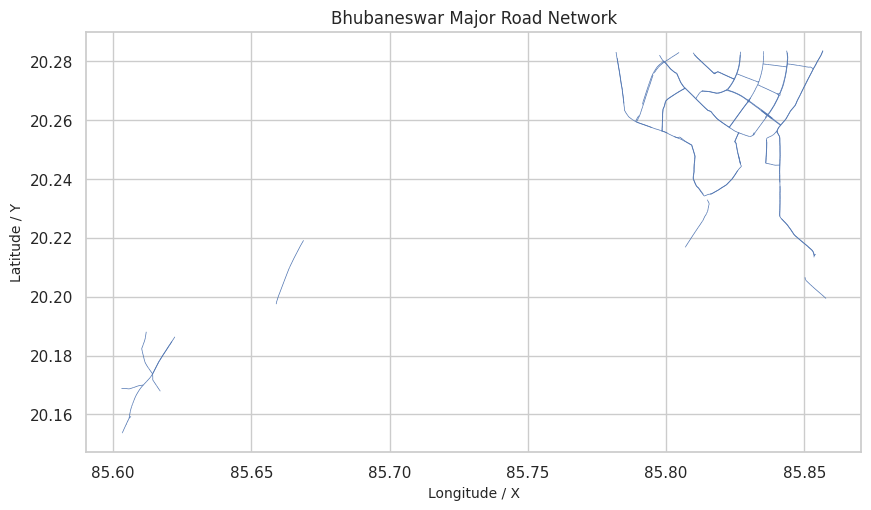

In [ ]:
major_roads = geo_data["major_roads.geojson"]

major_roads.plot(
    figsize=(10, 8),
    linewidth=0.5
)

plt.title("Bhubaneswar Major Road Network")
plt.xlabel("Longitude / X")
plt.ylabel("Latitude / Y")
plt.show()

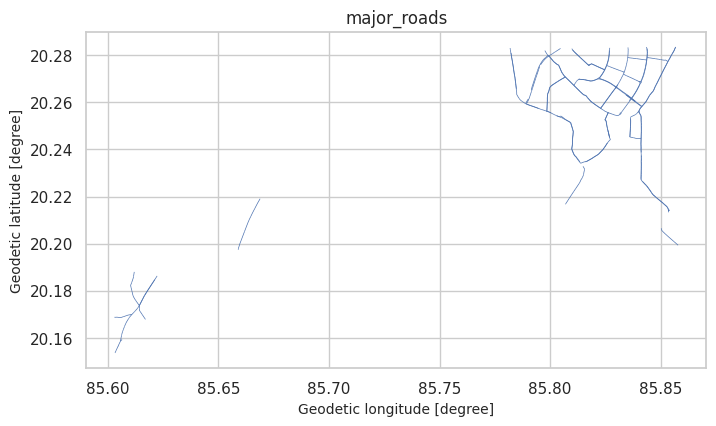

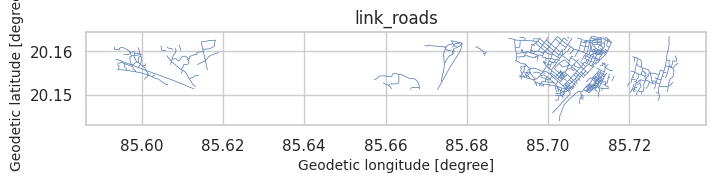

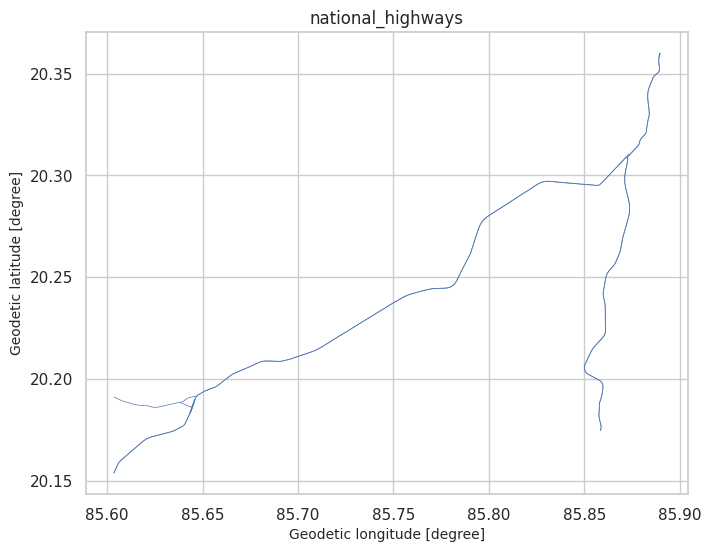

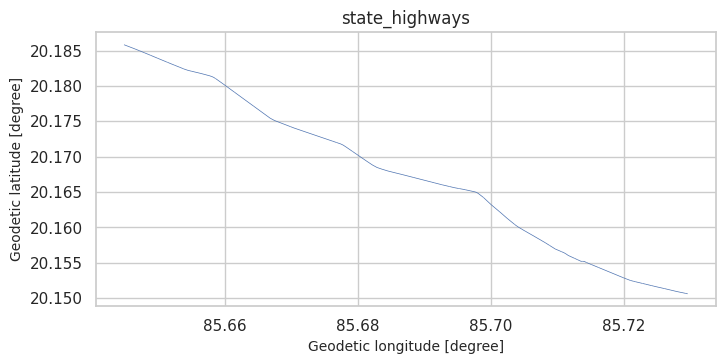

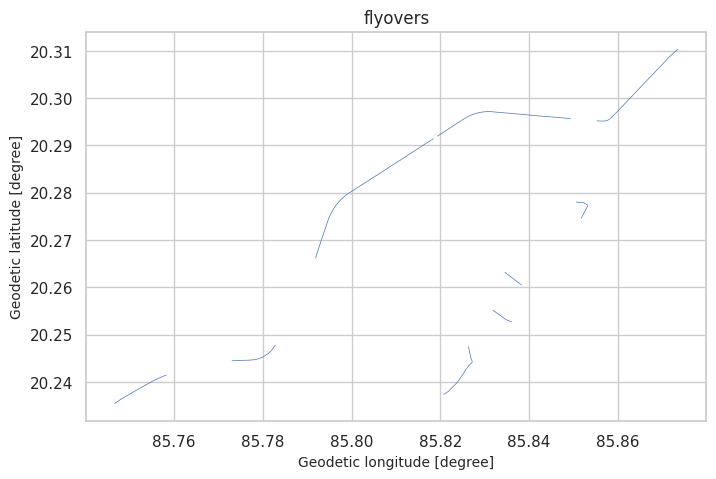

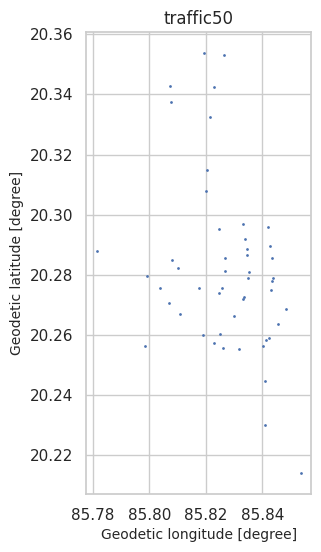

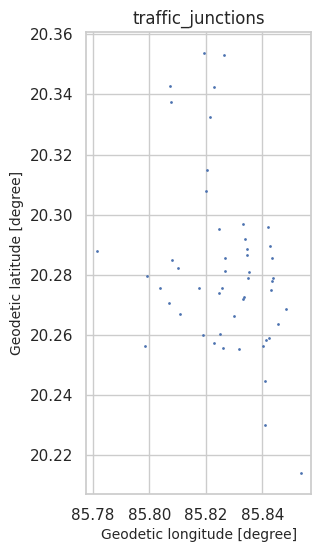

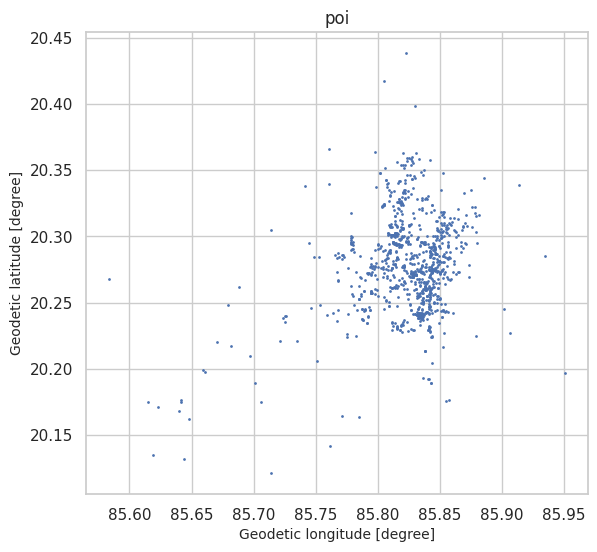

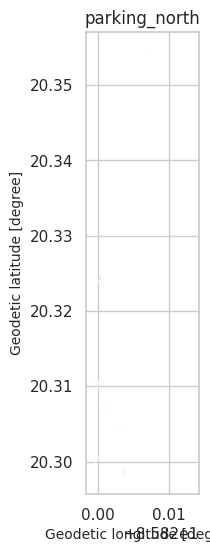

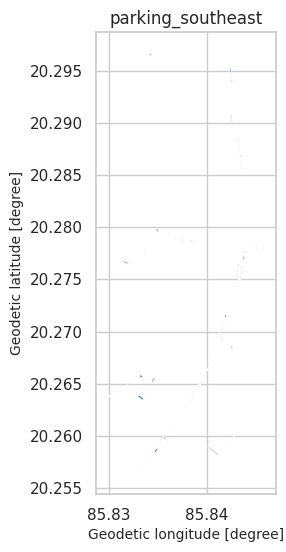

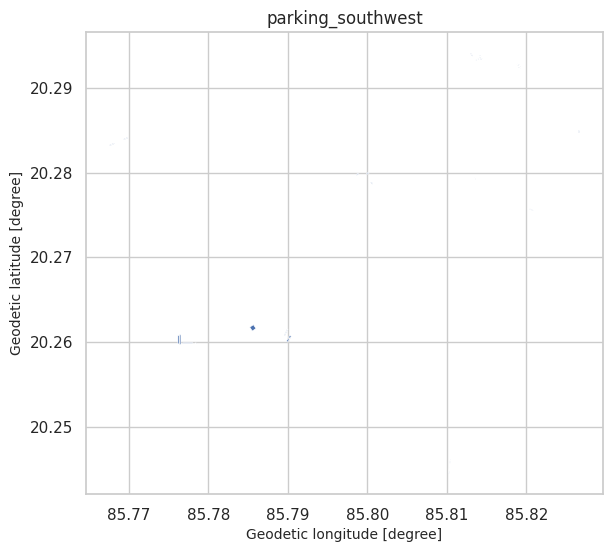

In [ ]:
for filename, gdf in geo_data.items():

    if gdf.empty:
        continue

    gdf.plot(
        figsize=(8, 6),
        markersize=2,
        linewidth=0.5
    )

    plt.title(filename.replace(".geojson", ""))
    plt.show()

In [ ]:
import os

ZOMATO_FOLDER = os.path.join(
    PROJECT_ROOT,
    "datasets ",
    "raw",
    "zomato"
)

print("Folder exists:", os.path.exists(ZOMATO_FOLDER))

if os.path.exists(ZOMATO_FOLDER):
    print("\nFiles inside Zomato folder:")
    print(os.listdir(ZOMATO_FOLDER))

Folder exists: False


In [ ]:
import os

MYDRIVE = "/content/drive/MyDrive"

print("Folders inside MyDrive:\n")

for item in os.listdir(MYDRIVE):
    print(repr(item))

Folders inside MyDrive:

'Colab Notebooks'
'Smart_Ride_Intelligence'


In [ ]:
for root, dirs, files in os.walk(MYDRIVE):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/raw/zomato/zomato_cleaned_dataset.csv
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_posts.csv
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_comments.csv
/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed/forum_training.csv


In [ ]:
ZOMATO_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/raw/zomato/zomato_cleaned_dataset.csv"

import pandas as pd
import os

if not os.path.exists(ZOMATO_PATH):
    raise FileNotFoundError("Zomato dataset not found!")

zomato = pd.read_csv(ZOMATO_PATH)

print("Zomato dataset loaded successfully!")
print("Dataset shape:", zomato.shape)

display(zomato.head())

Zomato dataset loaded successfully!
Dataset shape: (38964, 22)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow


In [ ]:
print("Dataset Shape:", zomato.shape)

print("\nFirst 5 Records:")
display(zomato.head())

print("\nColumn Names:")
print(zomato.columns.tolist())

print("\nData Types:")
print(zomato.dtypes)

print("\nDataset Information:")
zomato.info()

Dataset Shape: (38964, 22)

First 5 Records:


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow



Column Names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)', 'distance_km', 'delivery_speed']

Data Types:
ID                              object
Delivery_person_ID              object
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weather_conditions              object
Road_traffic_density            object
Vehicle_condition            

In [ ]:
zomato_missing = pd.DataFrame({
    "Missing_Count": zomato.isnull().sum(),
    "Missing_Percentage": (
        zomato.isnull().mean() * 100
    ).round(2)
})

display(
    zomato_missing.sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

print("\nTotal Missing Values:", zomato.isnull().sum().sum())

,Missing_Count,Missing_Percentage
Delivery_person_Ratings,1055,2.71
Delivery_person_Age,1019,2.62
Time_Orderd,835,2.14
Delivery_person_ID,0,0.00
Restaurant_latitude,0,0.00
ID,0,0.00
Restaurant_longitude,0,0.00
Delivery_location_latitude,0,0.00
Delivery_location_longitude,0,0.00
Order_Date,0,0.00



Total Missing Values: 2909


In [ ]:
print("Total Duplicate Rows:", zomato.duplicated().sum())

if "Delivery_person_ID" in zomato.columns:
    print(
        "Unique Delivery Persons:",
        zomato["Delivery_person_ID"].nunique()
    )

Total Duplicate Rows: 0
Unique Delivery Persons: 1170


In [ ]:
print("Numerical and Categorical Statistical Summary:")

display(zomato.describe(include="all").T)

Numerical and Categorical Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,38964,38964,0xcdcd,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,38964,1170,HYDRES04DEL02,64,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,37945.0,NaN,NaN,NaN,29.607089,5.763202,20.0,25.0,30.0,35.0,39.0
Delivery_person_Ratings,37909.0,NaN,NaN,NaN,4.631879,0.317006,2.5,4.5,4.7,4.9,5.0
Restaurant_latitude,38964.0,NaN,NaN,NaN,18.915583,5.460635,9.957144,12.986047,19.065838,22.751234,30.914057
Restaurant_longitude,38964.0,NaN,NaN,NaN,76.914536,3.498179,72.768726,73.897902,76.618203,78.368855,88.433452
Delivery_location_latitude,38964.0,NaN,NaN,NaN,18.979545,5.462504,9.967144,13.066047,19.124049,22.820072,31.054057
Delivery_location_longitude,38964.0,NaN,NaN,NaN,76.978498,3.498357,72.778726,73.938972,76.663067,78.405467,88.563452
Order_Date,38964,44,15-03-2022,1031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,38129,176,17:55,407,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
numerical_columns = zomato.select_dtypes(
    include=np.number
).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nNumerical Statistics:")
display(zomato[numerical_columns].describe().T)

Numerical Columns:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Vehicle_condition', 'multiple_deliveries', 'Time_taken (min)', 'distance_km']

Numerical Statistics:


,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,37945.0,29.607089,5.763202,20.000000,25.000000,30.000000,35.000000,39.000000
Delivery_person_Ratings,37909.0,4.631879,0.317006,2.500000,4.500000,4.700000,4.900000,5.000000
Restaurant_latitude,38964.0,18.915583,5.460635,9.957144,12.986047,19.065838,22.751234,30.914057
Restaurant_longitude,38964.0,76.914536,3.498179,72.768726,73.897902,76.618203,78.368855,88.433452
Delivery_location_latitude,38964.0,18.979545,5.462504,9.967144,13.066047,19.124049,22.820072,31.054057
Delivery_location_longitude,38964.0,76.978498,3.498357,72.778726,73.938972,76.663067,78.405467,88.563452
Vehicle_condition,38964.0,0.995534,0.817312,0.000000,0.000000,1.000000,2.000000,2.000000
multiple_deliveries,38964.0,0.749589,0.572172,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken (min),38964.0,26.581511,9.339546,10.000000,19.000000,26.000000,33.000000,54.000000
distance_km,38964.0,9.765092,5.605705,1.465067,4.658009,9.219906,13.681590,20.969489


In [ ]:
categorical_columns = zomato.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

for col in categorical_columns:

    print("\n" + "=" * 50)
    print("Column:", col)
    print("=" * 50)

    print(zomato[col].value_counts(dropna=False).head(15))

Categorical Columns:
['ID', 'Delivery_person_ID', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City', 'delivery_speed']

Column: ID
ID
0xcdcd    1
0xd987    1
0x2784    1
0xc8b6    1
0xdb64    1
0x3af3    1
0x3aab    1
0x689b    1
0xc9cf    1
0x36b8    1
0x5795    1
0x6c6b    1
0xb816    1
0x539b    1
0xa1b2    1
Name: count, dtype: int64

Column: Delivery_person_ID
Delivery_person_ID
HYDRES04DEL02       64
COIMBRES010DEL02    63
VADRES11DEL02       63
JAPRES14DEL02       63
RANCHIRES16DEL01    63
INDORES15DEL01      62
JAPRES03DEL01       62
JAPRES11DEL02       62
INDORES08DEL02      62
SURRES11DEL01       62
COIMBRES02DEL01     62
PUNERES06DEL02      62
JAPRES20DEL02       62
HYDRES13DEL02       61
SURRES01DEL02       61
Name: count, dtype: int64

Column: Order_Date
Order_Date
15-03-2022    1031
03-04-2022    1016
09-03-2022    1013
13-03-2022    1008
05-04-2022    1007
03-03-2022    1

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=zomato,
    x="time_taken",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Time Taken")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `time_taken` for `x`. An entry with this name does not appear in `data`.

<Figure size 900x500 with 0 Axes>

In [ ]:
print(zomato["time_taken"].dtype)

print(zomato["time_taken"].head(10))

print(zomato["time_taken"].unique()[:20])

KeyError: 'time_taken'

In [ ]:
print("Total columns:", len(zomato.columns))

for i, col in enumerate(zomato.columns):
    print(i, repr(col))

Total columns: 22
0 'ID'
1 'Delivery_person_ID'
2 'Delivery_person_Age'
3 'Delivery_person_Ratings'
4 'Restaurant_latitude'
5 'Restaurant_longitude'
6 'Delivery_location_latitude'
7 'Delivery_location_longitude'
8 'Order_Date'
9 'Time_Orderd'
10 'Time_Order_picked'
11 'Weather_conditions'
12 'Road_traffic_density'
13 'Vehicle_condition'
14 'Type_of_order'
15 'Type_of_vehicle'
16 'multiple_deliveries'
17 'Festival'
18 'City'
19 'Time_taken (min)'
20 'distance_km'
21 'delivery_speed'


In [ ]:
display(zomato.head())

print("\nDataset information:")
zomato.info()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),distance_km,delivery_speed
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,...,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,10.280582,Slow
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,...,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,6.242319,Average
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,...,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,13.787860,Average
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,...,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2.930258,Average
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,...,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19.396618,Slow



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38964 entries, 0 to 38963
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           38964 non-null  object 
 1   Delivery_person_ID           38964 non-null  object 
 2   Delivery_person_Age          37945 non-null  float64
 3   Delivery_person_Ratings      37909 non-null  float64
 4   Restaurant_latitude          38964 non-null  float64
 5   Restaurant_longitude         38964 non-null  float64
 6   Delivery_location_latitude   38964 non-null  float64
 7   Delivery_location_longitude  38964 non-null  float64
 8   Order_Date                   38964 non-null  object 
 9   Time_Orderd                  38129 non-null  object 
 10  Time_Order_picked            38964 non-null  object 
 11  Weather_conditions           38964 non-null  object 
 12  Road_traffic_density         38964 non-null  object 

In [ ]:
zomato.columns = (
    zomato.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print(zomato.columns.tolist())

['id', 'delivery_person_id', 'delivery_person_age', 'delivery_person_ratings', 'restaurant_latitude', 'restaurant_longitude', 'delivery_location_latitude', 'delivery_location_longitude', 'order_date', 'time_orderd', 'time_order_picked', 'weather_conditions', 'road_traffic_density', 'vehicle_condition', 'type_of_order', 'type_of_vehicle', 'multiple_deliveries', 'festival', 'city', 'time_taken_min', 'distance_km', 'delivery_speed']


In [ ]:
numeric_columns = [
    "time_taken_min",
    "distance_km",
    "delivery_person_age",
    "delivery_person_ratings",
    "vehicle_condition",
    "multiple_deliveries",
    "delivery_speed"
]

for col in numeric_columns:
    if col in zomato.columns:
        zomato[col] = pd.to_numeric(
            zomato[col],
            errors="coerce"
        )

print(zomato[numeric_columns].dtypes)

time_taken_min               int64
distance_km                float64
delivery_person_age        float64
delivery_person_ratings    float64
vehicle_condition            int64
multiple_deliveries        float64
delivery_speed             float64
dtype: object


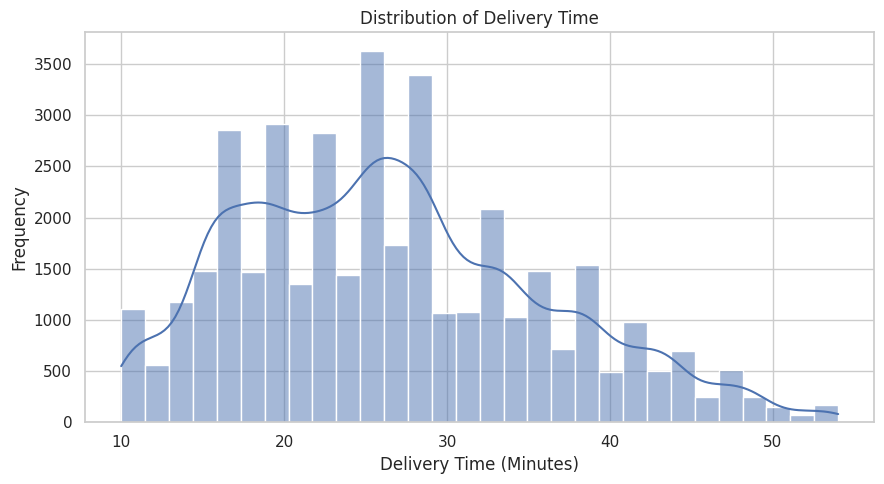

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=zomato,
    x="time_taken_min",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (Minutes)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

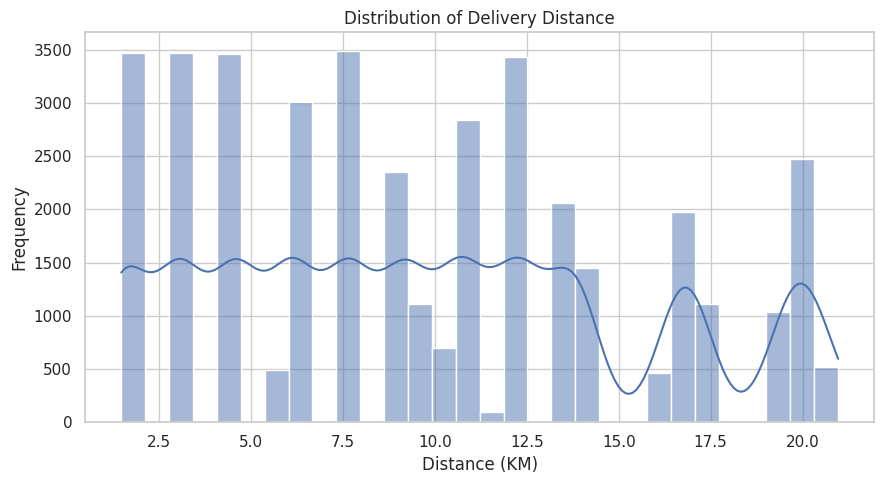

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=zomato,
    x="distance_km",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Distance")
plt.xlabel("Distance (KM)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

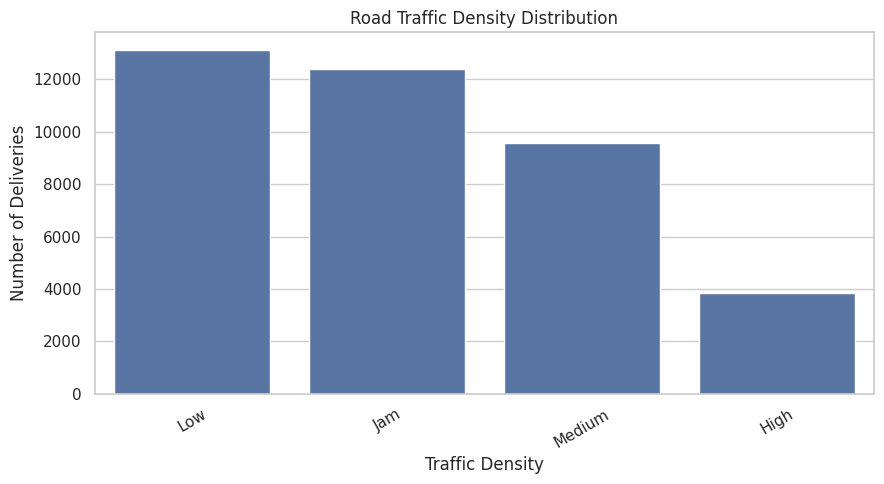

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=zomato,
    x="road_traffic_density",
    order=zomato["road_traffic_density"].value_counts().index
)

plt.title("Road Traffic Density Distribution")
plt.xlabel("Traffic Density")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

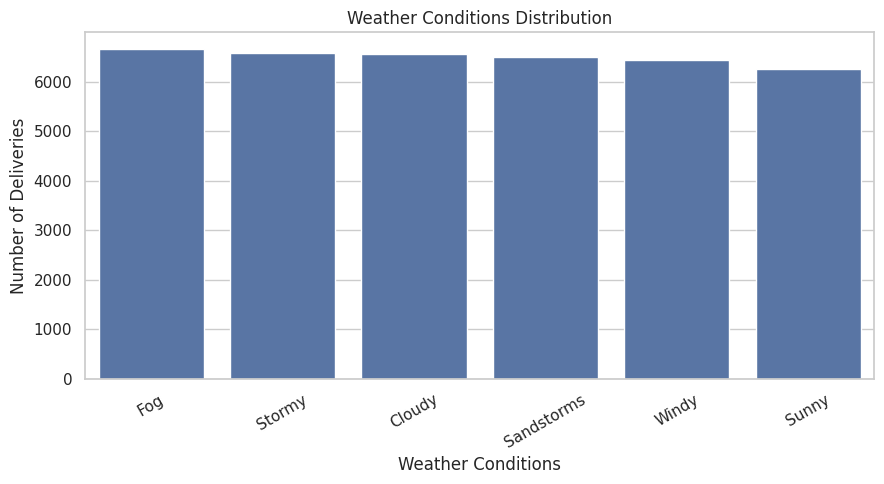

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=zomato,
    x="weather_conditions",
    order=zomato["weather_conditions"].value_counts().index
)

plt.title("Weather Conditions Distribution")
plt.xlabel("Weather Conditions")
plt.ylabel("Number of Deliveries")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

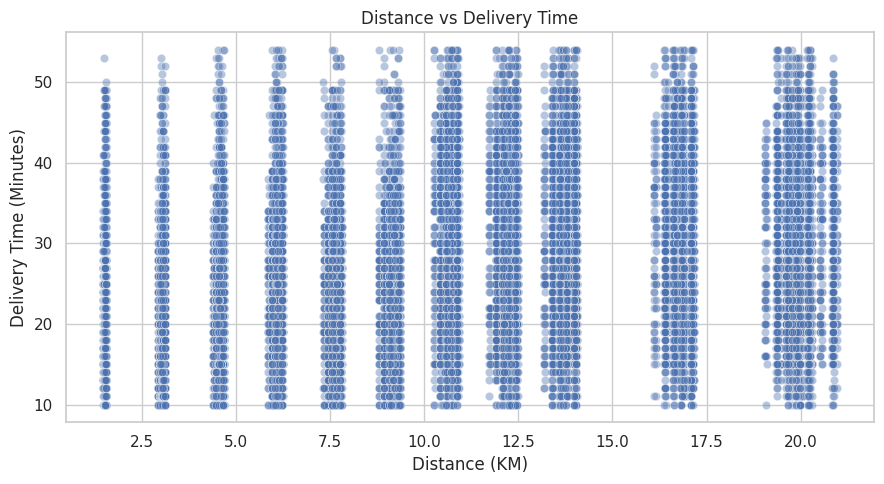

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=zomato,
    x="distance_km",
    y="time_taken_min",
    alpha=0.4
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (KM)")
plt.ylabel("Delivery Time (Minutes)")
plt.tight_layout()
plt.show()

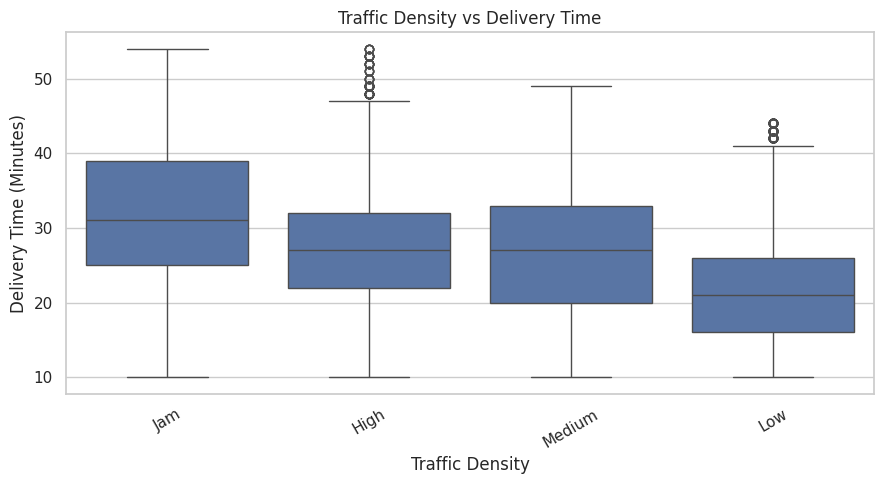

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=zomato,
    x="road_traffic_density",
    y="time_taken_min"
)

plt.title("Traffic Density vs Delivery Time")
plt.xlabel("Traffic Density")
plt.ylabel("Delivery Time (Minutes)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

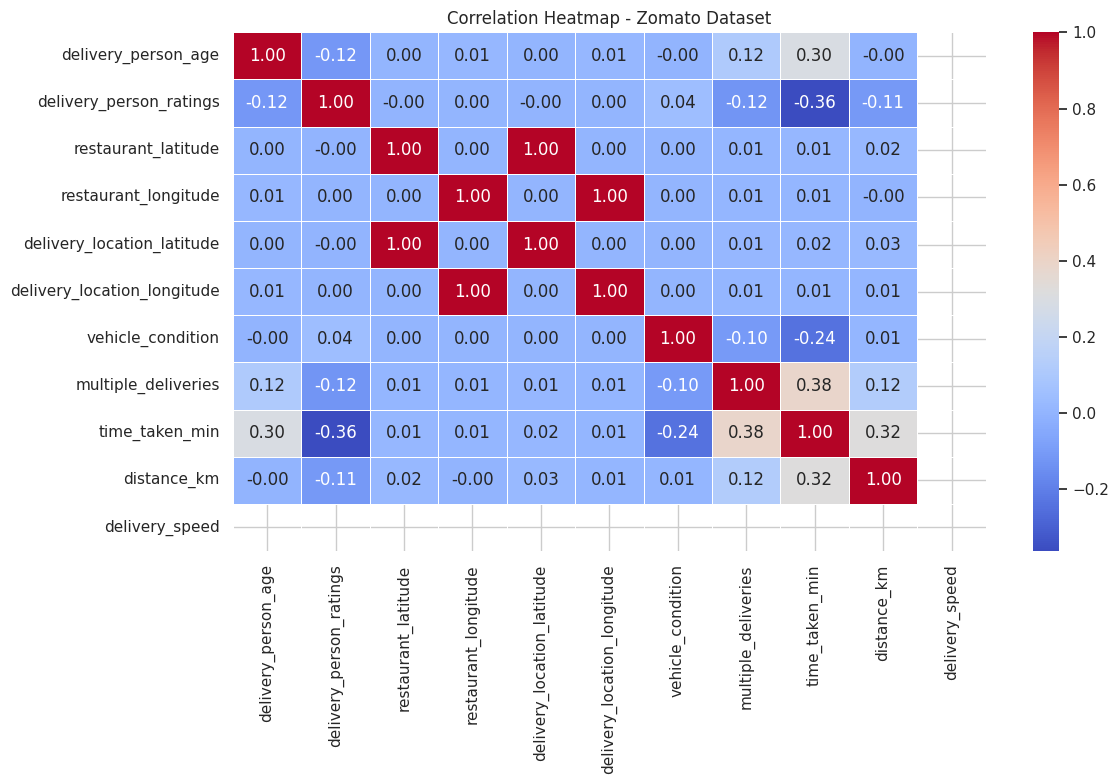

In [ ]:
plt.figure(figsize=(12, 8))

correlation = zomato.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Zomato Dataset")
plt.tight_layout()
plt.show()

In [ ]:
TARGET_COLUMN = "time_taken_min"

print("Target Variable:", TARGET_COLUMN)

print("\nTarget Data Type:")
print(zomato[TARGET_COLUMN].dtype)

print("\nTarget Statistics:")
display(zomato[TARGET_COLUMN].describe())

print("\nMissing Target Values:")
print(zomato[TARGET_COLUMN].isnull().sum())

Target Variable: time_taken_min

Target Data Type:
int64

Target Statistics:


,time_taken_min
count,38964.000000
mean,26.581511
std,9.339546
min,10.000000
25%,19.000000
50%,26.000000
75%,33.000000
max,54.000000



Missing Target Values:
0


In [ ]:
#inspecting forum datasets
PROCESSED_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence/datasets/processed"

posts = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_posts.csv")
)

comments = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_comments.csv")
)

training = pd.read_csv(
    os.path.join(PROCESSED_PATH, "forum_training.csv")
)

print("Forum Posts Shape:", posts.shape)
print("Forum Comments Shape:", comments.shape)
print("Forum Training Shape:", training.shape)

Forum Posts Shape: (1000, 21)
Forum Comments Shape: (1949, 8)
Forum Training Shape: (1000, 8)


In [ ]:
datasets = {
    "Forum Posts": posts,
    "Forum Comments": comments,
    "Forum Training": training
}

for name, df in datasets.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 3 Records:")
    display(df.head(3))


Forum Posts
Shape: (1000, 21)

Columns:
['post_id', 'user_id', 'title', 'text', 'category', 'subcategory', 'severity', 'location_name', 'latitude', 'longitude', 'created_at', 'observed_at', 'expires_at', 'sentiment', 'upvotes', 'comment_count', 'status', 'source_type', 'verification_status', 'is_synthetic', 'template_id']

First 3 Records:


,post_id,user_id,title,text,category,subcategory,severity,location_name,latitude,longitude,...,observed_at,expires_at,sentiment,upvotes,comment_count,status,source_type,verification_status,is_synthetic,template_id
0,P00001,U012,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,0,Medium,Bhubaneswar road segment,20.153729,85.720593,...,2026-11-09T18:34:13.247992105+05:30,2026-12-09T20:53:13.247992105+05:30,Negative,37,1,Active,synthetic,synthetic_unverified,True,Road Hazard_01
1,P00002,U026,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,0,Low,Bhubaneswar road segment,20.225751,85.813249,...,2026-10-25T20:20:43.053302191+05:30,2026-11-01T22:43:43.053302191+05:30,Positive,45,1,Expired,synthetic,synthetic_unverified,True,Route Tip_01
2,P00003,U090,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,1,Low,Bhubaneswar road segment,20.186956,85.630708,...,2026-11-12T17:02:59.198244989+05:30,2026-11-19T17:42:59.198244989+05:30,Positive,27,3,Active,synthetic,synthetic_unverified,True,Route Tip_02



Forum Comments
Shape: (1949, 8)

Columns:
['comment_id', 'post_id', 'user_id', 'comment_text', 'created_at', 'sentiment', 'source_type', 'is_synthetic']

First 3 Records:


,comment_id,post_id,user_id,comment_text,created_at,sentiment,source_type,is_synthetic
0,C000001,P00001,U038,Riders should remain cautious in this scenario.,2026-11-09T22:01:13.247992105+05:30,Negative,synthetic,True
1,C000002,P00002,U027,This alternative may be worth exploring.,2026-10-25T23:36:43.053302191+05:30,Positive,synthetic,True
2,C000003,P00003,U093,Thanks for sharing the suggestion.,2026-11-12T18:17:59.198244989+05:30,Positive,synthetic,True



Forum Training
Shape: (1000, 8)

Columns:
['post_id', 'title', 'text', 'category', 'severity', 'template_id', 'is_synthetic', 'combined_text']

First 3 Records:


,post_id,title,text,category,severity,template_id,is_synthetic,combined_text
0,P00001,Potholes reported near Bhubaneswar road segment,Several potholes are present on the road near ...,Road Hazard,Medium,Road Hazard_01,True,Potholes reported near Bhubaneswar road segmen...
1,P00002,Alternative route suggestion,An alternative road near Bhubaneswar road segm...,Route Tip,Low,Route Tip_01,True,Alternative route suggestion An alternative ro...
2,P00003,Suggested route for riders,Riders may consider exploring another connecti...,Route Tip,Low,Route Tip_02,True,Suggested route for riders Riders may consider...


In [ ]:
for name, df in datasets.items():

    print("\n", name)

    missing_report = pd.DataFrame({
        "Missing_Count": df.isnull().sum(),
        "Missing_Percentage": (
            df.isnull().mean() * 100
        ).round(2)
    })

    display(missing_report)


 Forum Posts


,Missing_Count,Missing_Percentage
post_id,0,0.0
user_id,0,0.0
title,0,0.0
text,0,0.0
category,0,0.0
subcategory,0,0.0
severity,0,0.0
location_name,0,0.0
latitude,0,0.0
longitude,0,0.0



 Forum Comments


,Missing_Count,Missing_Percentage
comment_id,0,0.0
post_id,0,0.0
user_id,0,0.0
comment_text,0,0.0
created_at,0,0.0
sentiment,0,0.0
source_type,0,0.0
is_synthetic,0,0.0



 Forum Training


,Missing_Count,Missing_Percentage
post_id,0,0.0
title,0,0.0
text,0,0.0
category,0,0.0
severity,0,0.0
template_id,0,0.0
is_synthetic,0,0.0
combined_text,0,0.0


In [ ]:
print("Duplicate Posts:", posts.duplicated().sum())
print("Duplicate Comments:", comments.duplicated().sum())
print("Duplicate Training Records:", training.duplicated().sum())

print("\nDuplicate Post IDs:", posts["post_id"].duplicated().sum())
print("Duplicate Comment IDs:", comments["comment_id"].duplicated().sum())

Duplicate Posts: 0
Duplicate Comments: 0
Duplicate Training Records: 0

Duplicate Post IDs: 0
Duplicate Comment IDs: 0


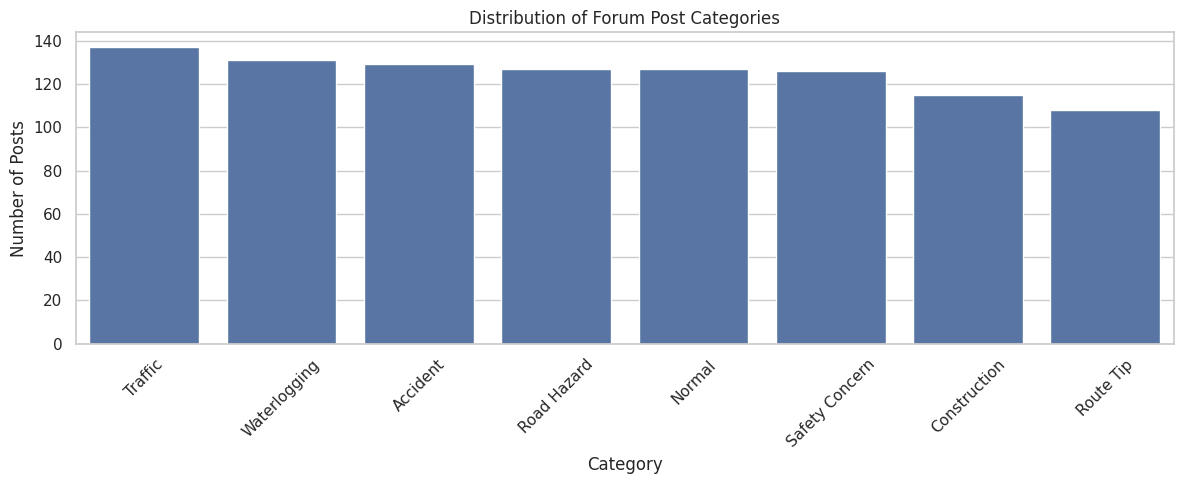

category
Traffic           137
Waterlogging      131
Accident          129
Road Hazard       127
Normal            127
Safety Concern    126
Construction      115
Route Tip         108
Name: count, dtype: int64


In [ ]:
plt.figure(figsize=(12, 5))

sns.countplot(
    data=posts,
    x="category",
    order=posts["category"].value_counts().index
)

plt.title("Distribution of Forum Post Categories")
plt.xlabel("Category")
plt.ylabel("Number of Posts")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

print(posts["category"].value_counts())

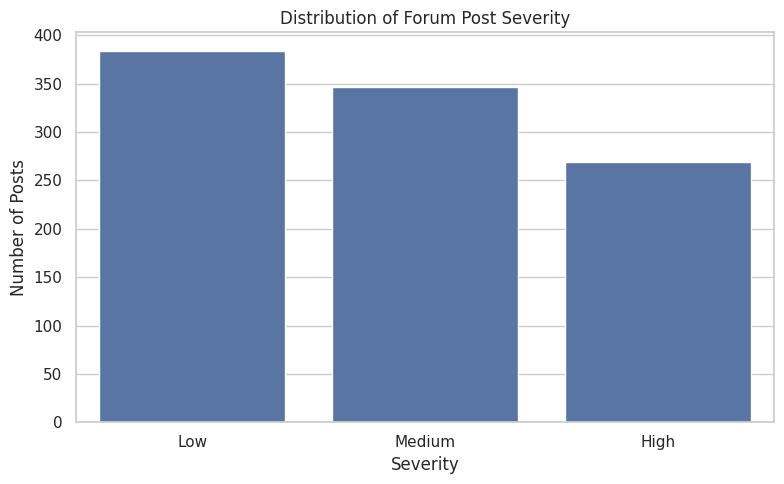

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=posts,
    x="severity",
    order=posts["severity"].value_counts().index
)

plt.title("Distribution of Forum Post Severity")
plt.xlabel("Severity")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

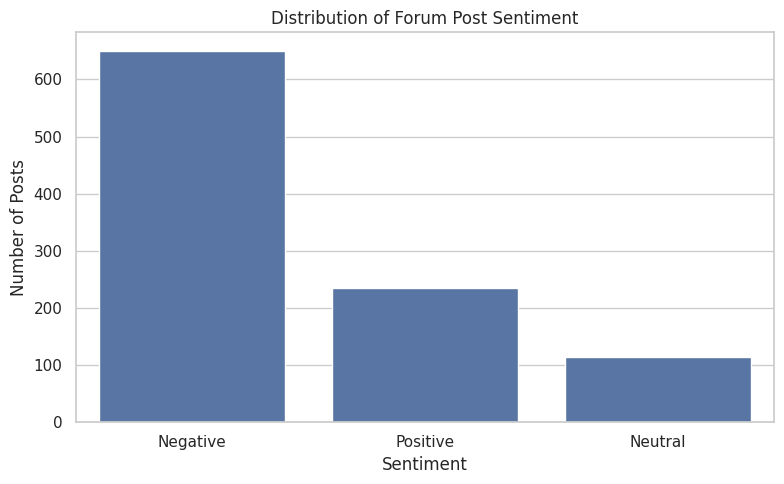

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=posts,
    x="sentiment",
    order=posts["sentiment"].value_counts().index
)

plt.title("Distribution of Forum Post Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Posts")

plt.tight_layout()
plt.show()

In [ ]:
invalid_comments = comments[
    ~comments["post_id"].isin(posts["post_id"])
]

print(
    "Comments without matching posts:",
    len(invalid_comments)
)

print(
    "Posts without comments:",
    len(
        set(posts["post_id"]) -
        set(comments["post_id"])
    )
)

Comments without matching posts: 0
Posts without comments: 0


In [ ]:
print("Training Dataset Shape:", training.shape)

print("\nCategory Distribution:")
print(training["category"].value_counts())

print("\nSample Training Text:")

display(
    training[["combined_text", "category"]].head(10)
)

Training Dataset Shape: (1000, 8)

Category Distribution:
category
Traffic           137
Waterlogging      131
Accident          129
Road Hazard       127
Normal            127
Safety Concern    126
Construction      115
Route Tip         108
Name: count, dtype: int64

Sample Training Text:


,combined_text,category
0,Potholes reported near Bhubaneswar road segmen...,Road Hazard
1,Alternative route suggestion An alternative ro...,Route Tip
2,Suggested route for riders Riders may consider...,Route Tip
3,Unsafe road conditions The road section near B...,Safety Concern
4,Unsafe road conditions The road section near B...,Safety Concern
5,Flooded road section A section of the road nea...,Waterlogging
6,Uneven road conditions Drivers may experience ...,Road Hazard
7,Waterlogging near Bhubaneswar road segment Wat...,Waterlogging
8,Temporary road diversion A temporary traffic d...,Construction
9,Poor visibility at night Visibility may be red...,Safety Concern


In [ ]:
#Create a consolidated dataset inventory
inventory = []

# GeoJSON datasets
for filename, gdf in geo_data.items():

    inventory.append({
        "Dataset": filename,
        "Type": "GeoJSON",
        "Records": len(gdf),
        "Columns": len(gdf.columns),
        "Missing_Values": int(gdf.isnull().sum().sum()),
        "Details": str(gdf.crs)
    })

# Zomato dataset
inventory.append({
    "Dataset": "zomato_cleaned_dataset.csv",
    "Type": "CSV",
    "Records": len(zomato),
    "Columns": len(zomato.columns),
    "Missing_Values": int(zomato.isnull().sum().sum()),
    "Details": "Travel-time prediction"
})

# Forum datasets
for name, df in datasets.items():

    inventory.append({
        "Dataset": name,
        "Type": "CSV",
        "Records": len(df),
        "Columns": len(df.columns),
        "Missing_Values": int(df.isnull().sum().sum()),
        "Details": "Forum intelligence"
    })

inventory_df = pd.DataFrame(inventory)

display(inventory_df)

,Dataset,Type,Records,Columns,Missing_Values,Details
0,major_roads.geojson,GeoJSON,1000,11,1129,EPSG:4326
1,link_roads.geojson,GeoJSON,1000,11,1953,EPSG:4326
2,national_highways.geojson,GeoJSON,456,11,30,EPSG:4326
3,state_highways.geojson,GeoJSON,76,11,0,EPSG:4326
4,flyovers.geojson,GeoJSON,42,11,165,EPSG:4326
5,traffic50.geojson,GeoJSON,50,12,0,EPSG:4326
6,traffic_junctions.geojson,GeoJSON,50,12,0,EPSG:4326
7,poi.geojson,GeoJSON,1000,3,0,EPSG:4326
8,parking_north.geojson,GeoJSON,21,15,21,EPSG:4326
9,parking_southeast.geojson,GeoJSON,74,15,76,EPSG:4326


In [ ]:
OUTPUT_PATH = "/content/drive/MyDrive/Smart_Ride_Intelligence/reports"

os.makedirs(OUTPUT_PATH, exist_ok=True)

# Main inventory
inventory_df.to_csv(
    os.path.join(OUTPUT_PATH, "dataset_inventory.csv"),
    index=False
)

# GIS inventory
geo_inventory_df.to_csv(
    os.path.join(OUTPUT_PATH, "geojson_inventory.csv"),
    index=False
)

# GIS bounds
bounds_df.to_csv(
    os.path.join(OUTPUT_PATH, "geojson_bounds.csv"),
    index=False
)

# Zomato missing values
zomato_missing.to_csv(
    os.path.join(OUTPUT_PATH, "zomato_missing_values.csv")
)

print("All inventory reports saved successfully!")
print("Saved location:", OUTPUT_PATH)

All inventory reports saved successfully!
Saved location: /content/drive/MyDrive/Smart_Ride_Intelligence/reports
